In [4]:
# ============================================================
# [CELL 1] MOUNT GOOGLE DRIVE
# ============================================================
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
# ============================================================
# [CELL 2] SETUP - Cai dat & kiem tra moi truong
# ============================================================
!pip install -q ultralytics
import ultralytics, torch, os
ultralytics.checks()
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHONG co GPU!")

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.3/112.6 GB disk)
GPU: Tesla T4


In [8]:
# ============================================================
# [CELL 3] COPY DATASET -> /content (train nhanh, tranh doc Drive)
# ============================================================
import os, shutil, time

# --- Nguon tren Drive (tap da chia 70/15/15) ---
DRIVE_DIR = "/content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 2020.v1i.yolov8_701515"
# --- Dich tren o cuc bo cua Colab (doc/ghi cuc nhanh) ---
LOCAL_DIR = "/content/hcmc_701515"

t0 = time.time()
if os.path.exists(LOCAL_DIR):
    shutil.rmtree(LOCAL_DIR)
shutil.copytree(DRIVE_DIR, LOCAL_DIR)

print(f"Da copy dataset vao {LOCAL_DIR}  ({time.time()-t0:.1f}s)")
print("Kiem tra thu muc:", os.listdir(LOCAL_DIR))

Da copy dataset vao /content/hcmc_701515  (766.7s)
Kiem tra thu muc: ['val', 'data.yaml', 'test', 'train']


In [ ]:
# ============================================================
# [CELL 4] PATH - Khai bao duong dan
# ============================================================
# --- data.yaml tro vao LOCAL (khong phai Drive) de train nhanh ---
DATA_YAML  = "/content/hcmc_701515/data.yaml"

# --- Weights khoi tao = best.pt cua fine-tune CanTho ---
PRETRAINED = "/content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/finetune_cantho/weights/best.pt"

# --- Noi luu ket qua: VAN de tren Drive de KHONG mat khi Colab reset ---
PROJECT = "/content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline"
NAME    = "finetune_hcmc_701515"

# --- Neu data.yaml chua co trong ban local -> tao moi (tro path local) ---
if not os.path.exists(DATA_YAML):
    print("Chua thay data.yaml trong ban local -> tao moi.")
    names = ['car', 'motorbike', 'truck', 'bus']   # <-- SUA cho dung thu tu lop cua bo anh
    nc    = len(names)
    with open(DATA_YAML, "w") as f:
        f.write(f"path: /content/hcmc_701515\n"
                f"train: train/images\n"
                f"val: val/images\n"
                f"test: test/images\n\n"
                f"nc: {nc}\n"
                f"names: {names}\n")

# --- Kiem tra ton tai truoc khi chay ---
assert os.path.exists(DATA_YAML),  f"Khong thay data.yaml: {DATA_YAML}"
assert os.path.exists(PRETRAINED), f"Khong thay best.pt CanTho: {PRETRAINED}"

print("DATA_YAML :", DATA_YAML)
print("PRETRAINED:", PRETRAINED)
print("Ket qua se luu tai:", os.path.join(PROJECT, NAME))

DATA_YAML : /content/hcmc_701515/data.yaml
PRETRAINED: /content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/finetune_cantho/weights/best.pt
Ket qua se luu tai: /content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/finetune_hcmc_701515


In [ ]:
# ============================================================
# [CELL 5] TRAIN - Fine-tune YOLOv8 tren tap HCM 701515
# ============================================================
from ultralytics import YOLO

model = YOLO(PRETRAINED)

results = model.train(
    data      = DATA_YAML,
    epochs    = 100,        # co the tang/giam tuy thoi gian
    imgsz     = 640,
    batch     = 16,         # giam xuong 8 neu bao loi CUDA out of memory
    patience  = 20,         # early stopping neu 20 epoch khong cai thien
    lr0       = 0.001,      # learning rate THAP cho fine-tune
    optimizer = "auto",
    seed      = 42,         # tai lap ket qua (giu giong cac model khac de so sanh)
    project   = PROJECT,
    name      = NAME,
    exist_ok  = True,
    plots     = True,       # xuat training curve, confusion matrix...
)

Ultralytics 8.4.126 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hcmc_701515/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/finetune_cantho/weights/

KeyboardInterrupt: 

In [ ]:
# Qua trinh train bi treo, cell nay chay tiep tu LAST da luu #
from ultralytics import YOLO
model = YOLO(os.path.join(PROJECT, NAME, "weights", "last.pt"))
model.train(resume=True)

Ultralytics 8.4.126 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hcmc_701515/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/finetune_hcmc_701515/wei

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79e379289b00>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [ ]:
# ============================================================
# [CELL 6] EVAL - Danh gia tren tap TEST (15%)
# ============================================================
best_model = YOLO(os.path.join(PROJECT, NAME, "weights", "best.pt"))

metrics = best_model.val(
    data     = DATA_YAML,
    split    = "test",      # danh gia rieng tren tap test
    imgsz    = 640,
    project  = PROJECT,
    name     = NAME + "_test",
    exist_ok = True,
)

print("================ KET QUA TREN TAP TEST ================")
print(f"mAP@0.5      : {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95 : {metrics.box.map:.4f}")
print(f"Precision    : {metrics.box.mp:.4f}")
print(f"Recall       : {metrics.box.mr:.4f}")
print("======================================================")

Ultralytics 8.4.126 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.1 ms, read: 45.1±23.0 MB/s, size: 60.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 2020.v1i.yolov8_701515/test/labels... 2267 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2267/2267 200.8it/s 11.3s
val: /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 2020.v1i.yolov8_701515/test/images/cam_01_000596_jpg.rf.e27909b3bca621ade420095897f7c5e7.jpg: 1 duplicate labels removed
val: /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 2020.v1i.yolov8_701515/test/images/cam_01_001195_jpg.rf.99126ca4b71bfad3e186294ec9f1f02f.jpg: 1 duplica

----- results.png -----


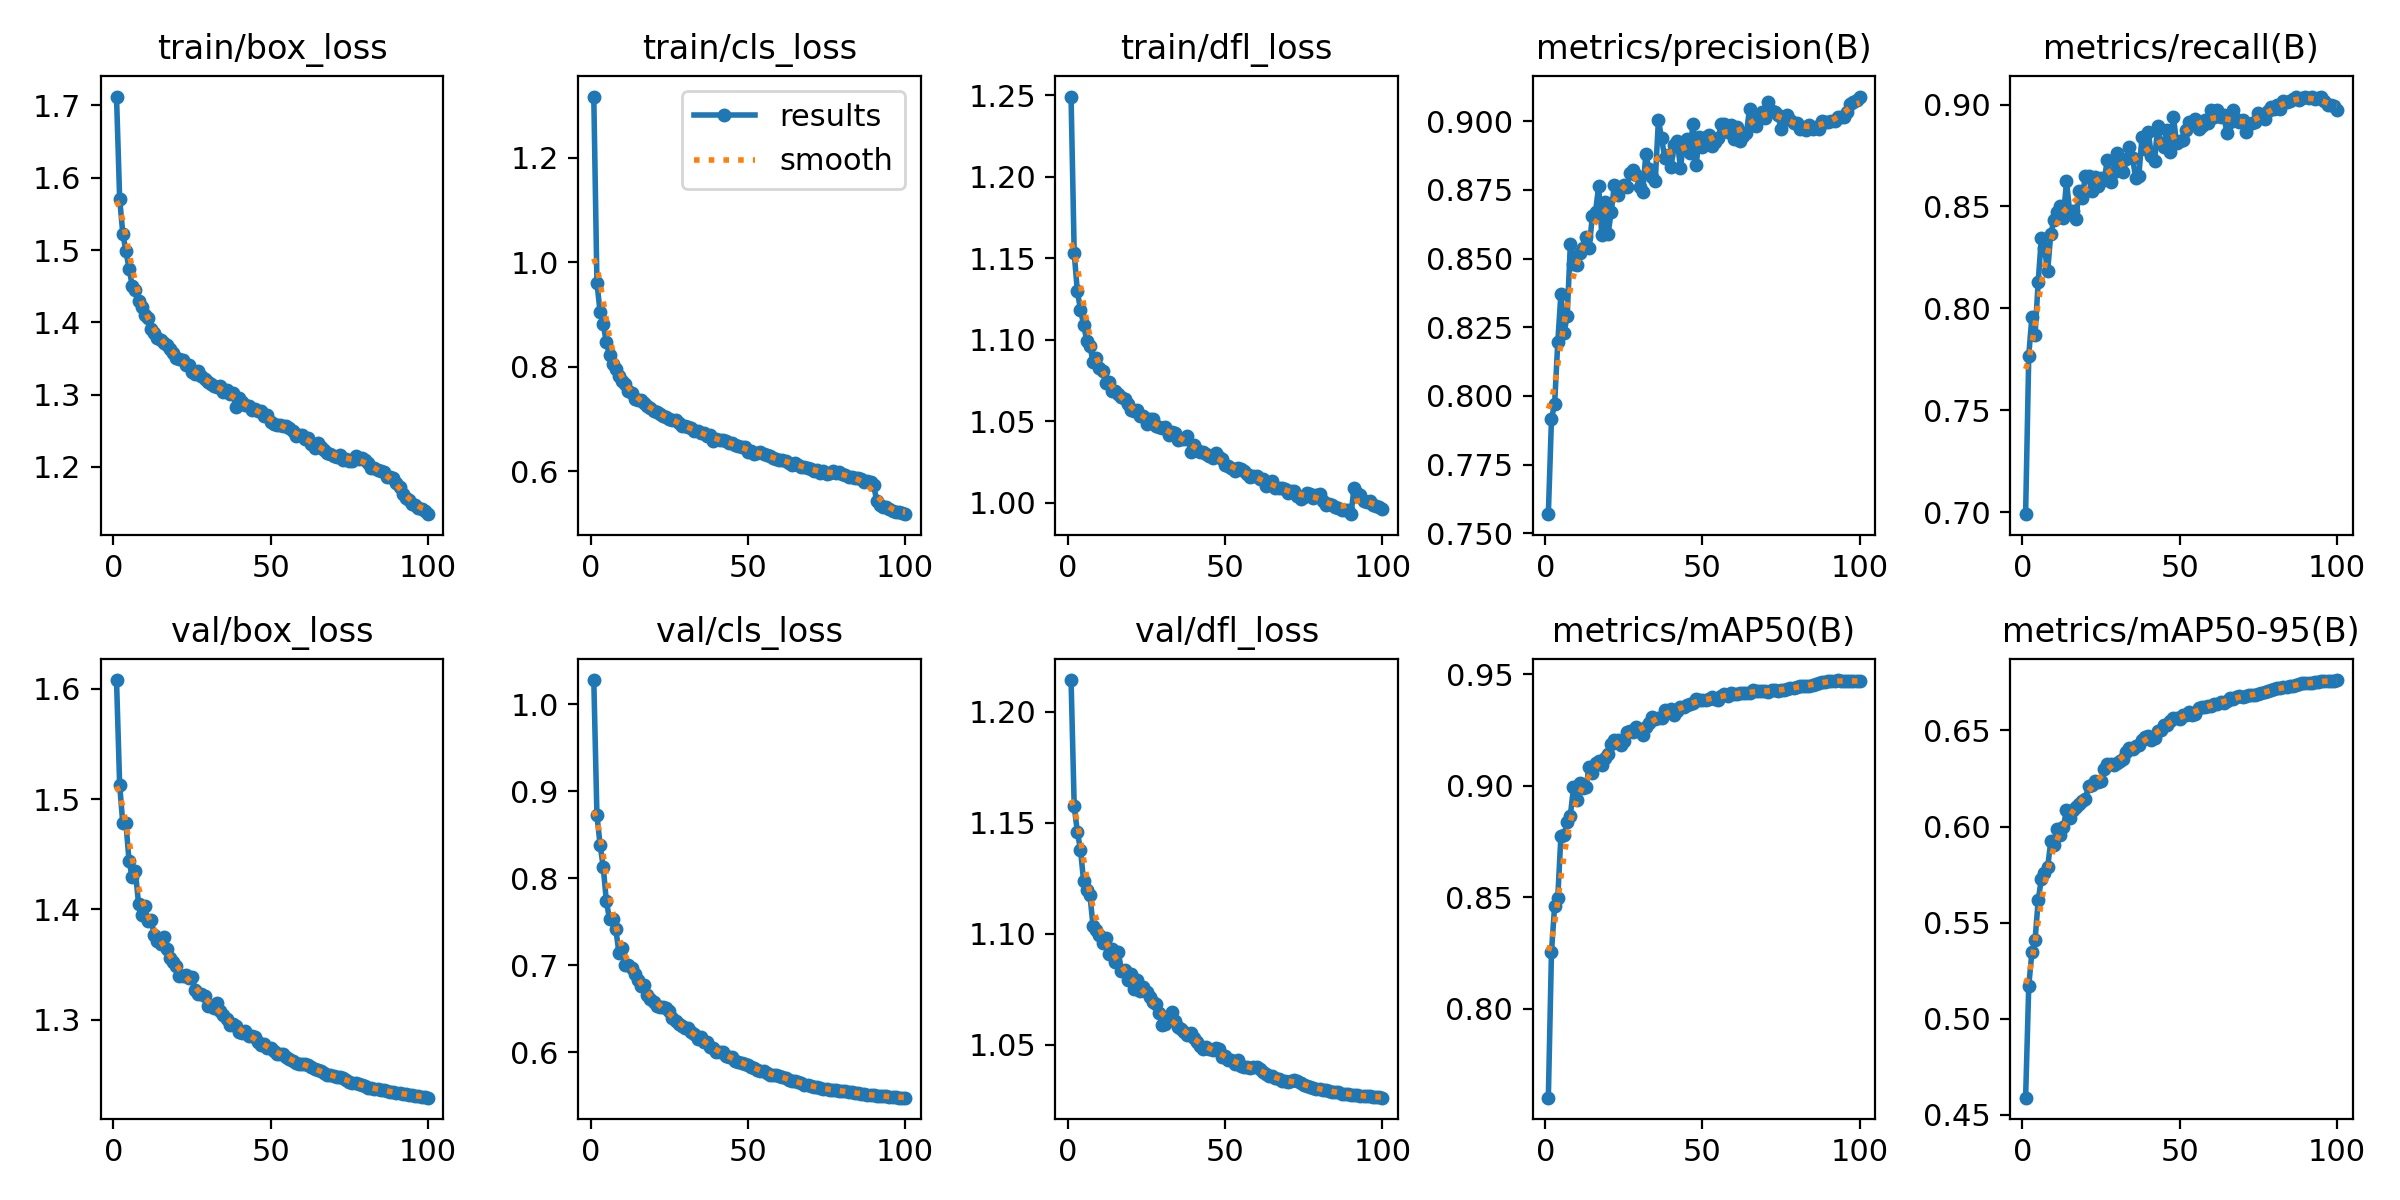

----- confusion_matrix.png -----


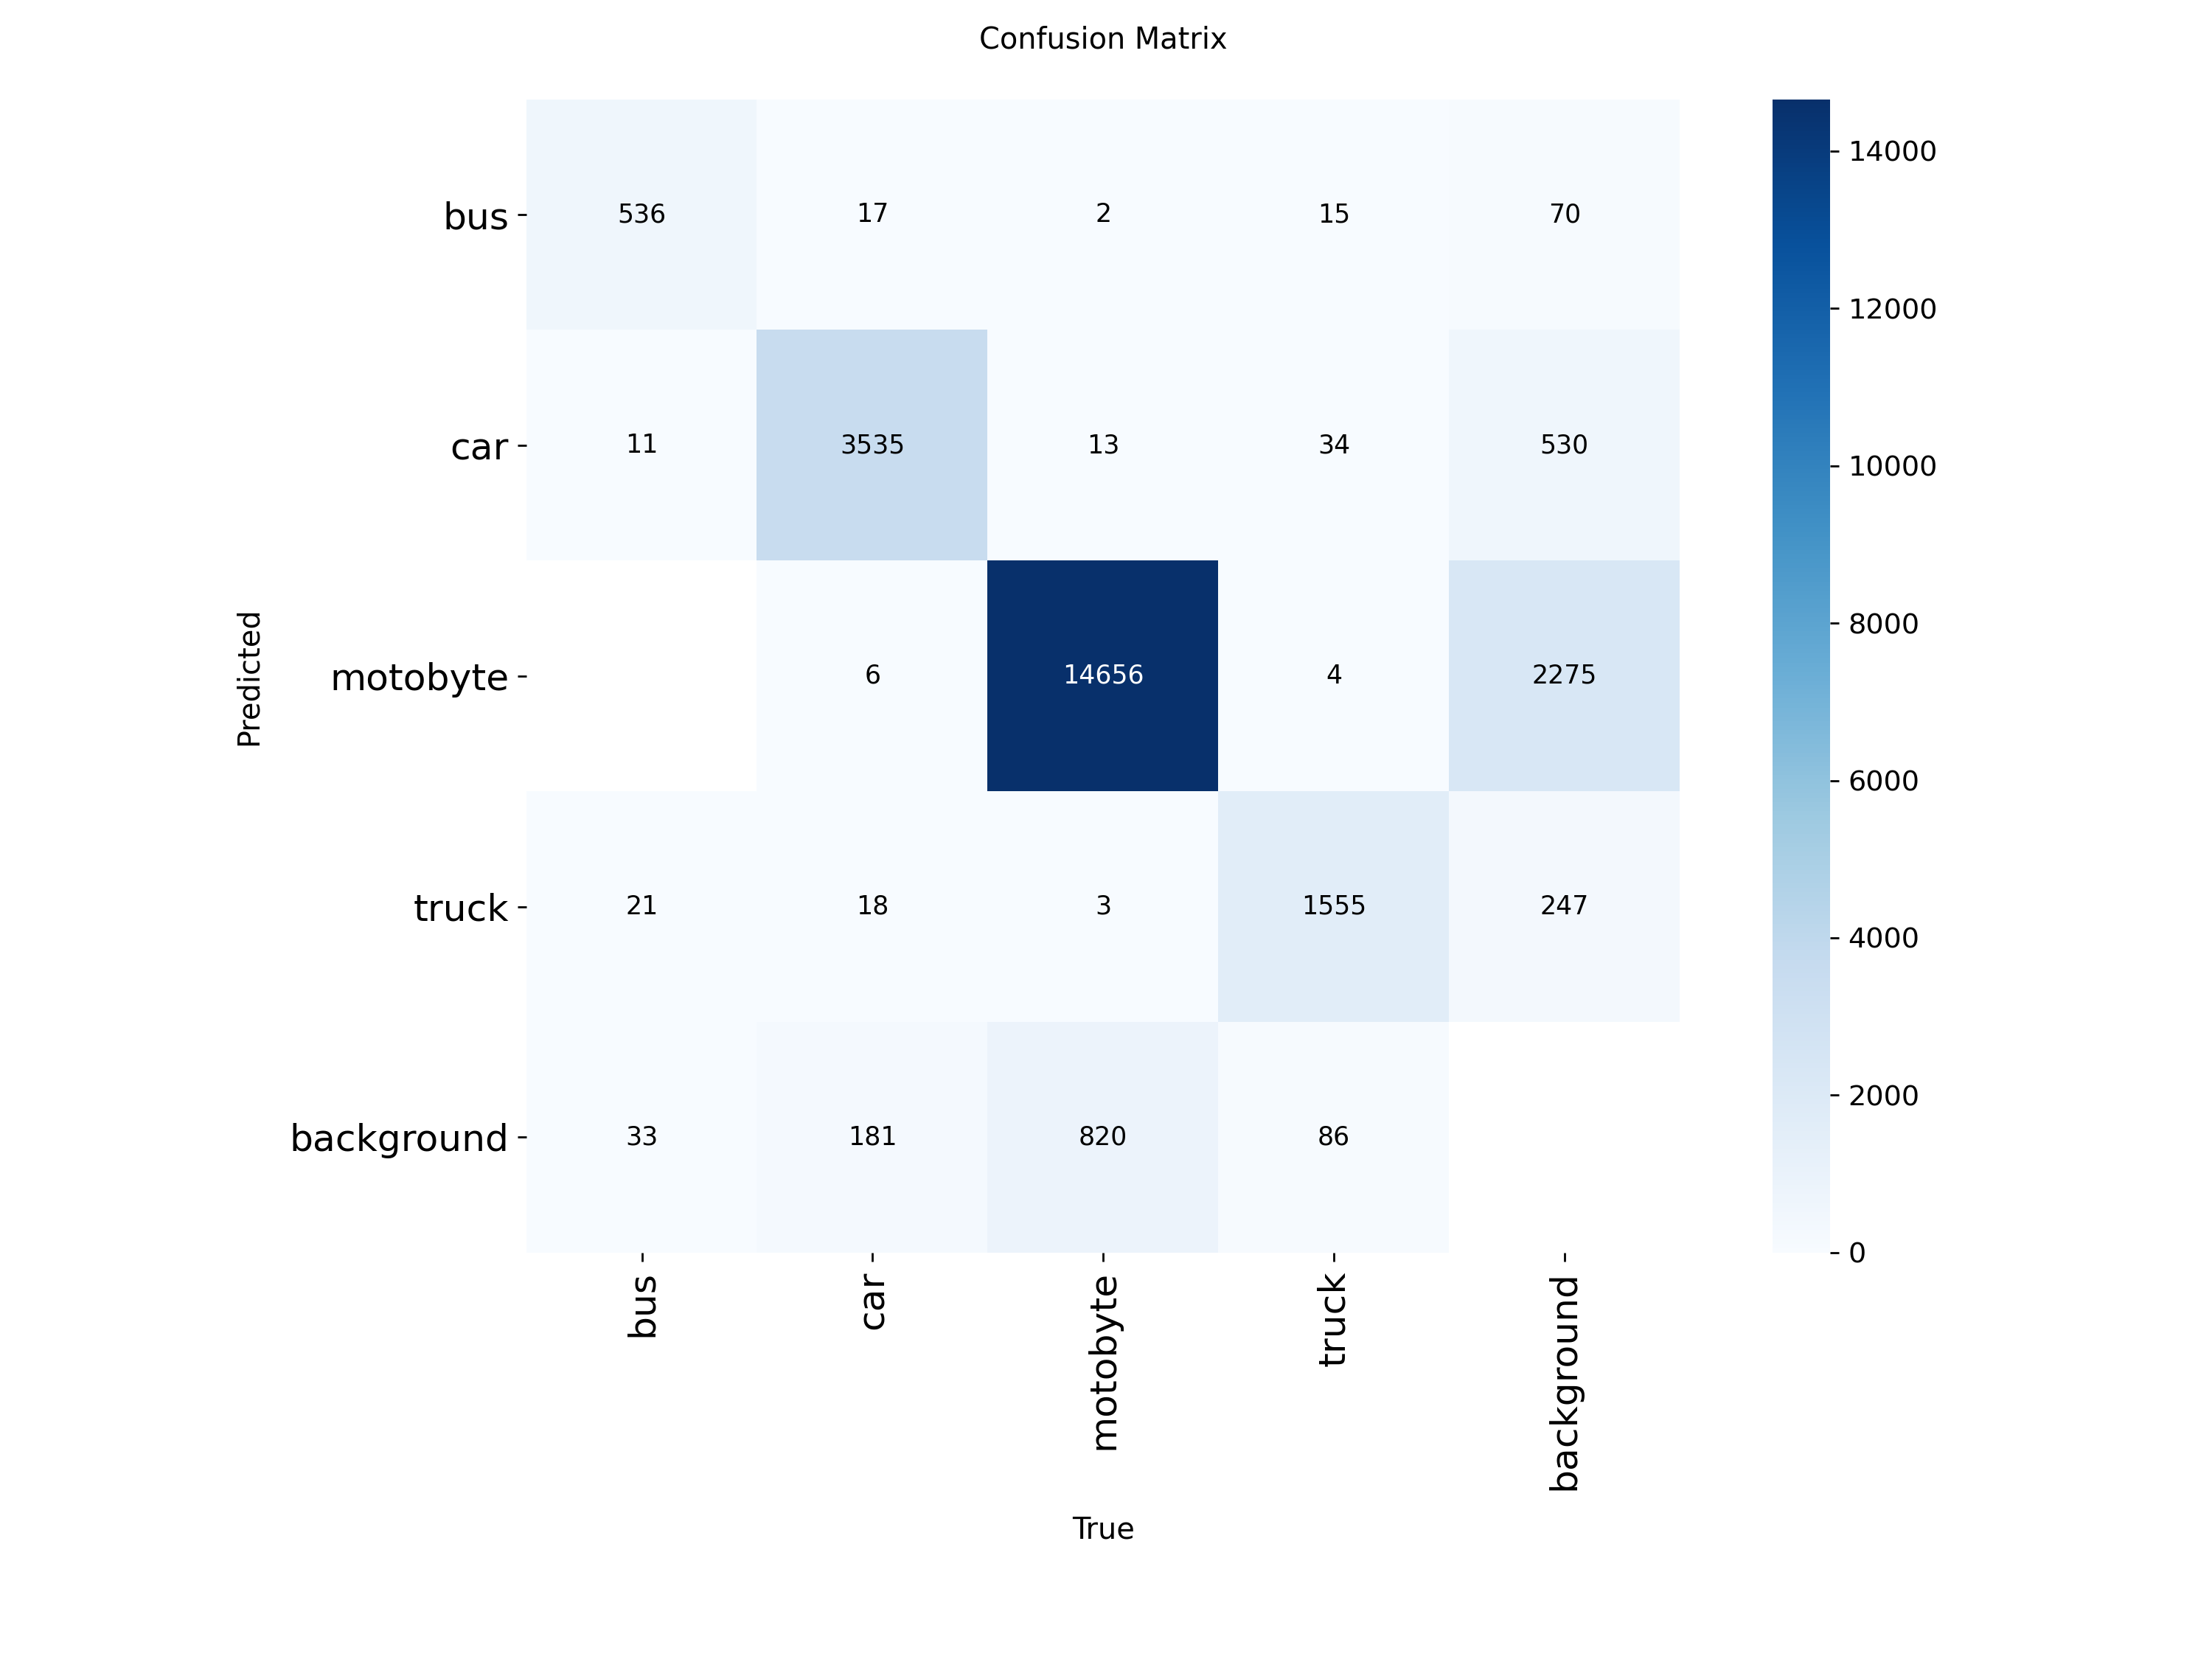

In [ ]:
# ============================================================
# [CELL 7] Xem nhanh cac bieu do ket qua
# ============================================================
from IPython.display import Image, display
res_dir = os.path.join(PROJECT, NAME)
for f in ["results.png", "confusion_matrix.png", "PR_curve.png"]:
    p = os.path.join(res_dir, f)
    if os.path.exists(p):
        print(f"----- {f} -----")
        display(Image(filename=p))

In [9]:
# ============================================================
# [CELL 8 - SUA LAI] Danh gia model CANTHO (TRUOC khi vao GD3)
# TREN CHINH tap test HCMC, de co phep so sanh HOP LE
# (cung 1 test set, dung nguyen tac da thong nhat)
# ============================================================
from ultralytics import YOLO

model_cantho_before = YOLO("/content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/finetune_cantho/weights/best.pt")

metrics_before = model_cantho_before.val(
    data     = DATA_YAML,        # QUAN TRONG: van la file yaml cua HCMC
    split    = "test",
    imgsz    = 640,
    project  = PROJECT,
    name     = "eval_cantho_on_hcmc_test",
    exist_ok = True,
)

print("===== MODEL CANTHO (TRUOC GD3) - TREN TEST HCMC =====")
print("mAP@0.5      :", round(metrics_before.box.map50, 4))
print("mAP@0.5:0.95 :", round(metrics_before.box.map, 4))
print("Precision    :", round(metrics_before.box.mp, 4))
print("Recall       :", round(metrics_before.box.mr, 4))
print("mAP@0.5 tung lop:")
names = model_cantho_before.names
for i in range(len(metrics_before.box.ap_class_index)):
    c = metrics_before.box.ap_class_index[i]
    print(" ", names[c], "->", round(metrics_before.box.ap50[i], 4))

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.0 ms, read: 57.8±24.8 MB/s, size: 70.4 KB)
val: Scanning /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 2020.v1i.yolov8_701515/test/labels.cache... 2267 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2267/2267 194.1Mit/s 0.0s
val: /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 2020.v1i.yolov8_701515/test/images/cam_01_000596_jpg.rf.e27909b3bca621ade420095897f7c5e7.jpg: 1 duplicate labels removed
val: /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 2020.v1i.yolov8_701515/test/images/cam_01_001195_jpg.rf.99126ca4b71bfad3e186294ec9f1f02f.jpg: 1 duplicate labels removed
val: /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 2020.v1i.yolov8_701515/test/images/cam_04_004334_

In [11]:
from ultralytics import YOLO
import os

# Duong dan day du, viet cung de tranh phu thuoc bien co the bi mat
BEST_HCMC_PATH = "/content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/finetune_hcmc_701515/weights/best.pt"
DATA_YAML = "/content/hcmc_701515/data.yaml"

# Kiem tra ton tai truoc khi chay, tranh loi mo ho
print("Model HCMC ton tai:", os.path.exists(BEST_HCMC_PATH))
print("Data yaml ton tai:", os.path.exists(DATA_YAML))

best_model = YOLO(BEST_HCMC_PATH)
metrics = best_model.val(
    data     = DATA_YAML,
    split    = "test",
    imgsz    = 640,
    project  = "/content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline",
    name     = "finetune_hcmc_701515_test",
    exist_ok = True,
)

print("================ KET QUA TREN TAP TEST HCMC ================")
print(f"mAP@0.5      : {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95 : {metrics.box.map:.4f}")
print(f"Precision    : {metrics.box.mp:.4f}")
print(f"Recall       : {metrics.box.mr:.4f}")

print("\nmAP@0.5 tung lop:")
names = best_model.names
for i in range(len(metrics.box.ap_class_index)):
    c = metrics.box.ap_class_index[i]
    print(" ", names[c], "->", round(metrics.box.ap50[i], 4))

Model HCMC ton tai: True
Data yaml ton tai: True
Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 52.9±21.6 MB/s, size: 67.7 KB)
val: Scanning /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 2020.v1i.yolov8_701515/test/labels.cache... 2267 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2267/2267 475.4Mit/s 0.0s
val: /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 2020.v1i.yolov8_701515/test/images/cam_01_000596_jpg.rf.e27909b3bca621ade420095897f7c5e7.jpg: 1 duplicate labels removed
val: /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 2020.v1i.yolov8_701515/test/images/cam_01_001195_jpg.rf.99126ca4b71bfad3e186294ec9f1f02f.jpg: 1 duplicate labels removed
val: /content/drive/MyDrive/Do an AI giao thong/Dataset/Vehicle Counting AIC HCMC 